In [1]:
%pip -q install scikit-learn seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, f1_score,
    ConfusionMatrixDisplay, confusion_matrix
)

In [3]:
uploaded = files.upload()
nama_file = next(iter(uploaded))
data = pd.read_csv(nama_file)

print("Ukuran dataset:", data.shape)
display(data.head())
display(data['driver_label'].value_counts().rename('jumlah data').to_frame())

Saving dataset_dummy_alert_deforestasi.csv to dataset_dummy_alert_deforestasi (1).csv
Ukuran dataset: (700, 10)


,alert_id,bulan,wilayah,luas_perubahan_ha,indikator_kedekatan_jalan_0_1,indikator_kebakaran_0_1,indikator_air_banjir_0_1,ketersediaan_optik_0_1,sinyal_radar_0_1,driver_label
0,ALR0001,2025-02,Borneo,1.85,0.401,0.422,0.000,0.751,0.667,Pertanian skala kecil
1,ALR0002,2023-04,Borneo,5.05,0.695,0.362,0.629,0.316,0.766,Pertambangan
2,ALR0003,2024-01,Amerika Selatan,2.47,0.850,0.386,0.000,0.877,0.775,Penebangan selektif
3,ALR0004,2023-03,Asia Tenggara,6.97,0.444,0.275,0.390,0.708,0.707,Pertanian skala besar
4,ALR0005,2023-06,Amerika Selatan,1.86,0.542,0.051,0.295,0.936,0.685,Pertanian skala besar


,jumlah data
driver_label,
Pertanian skala kecil,155
Penebangan selektif,123
Pertanian skala besar,121
Kebakaran,109
Pertambangan,98
Gangguan alami/banjir,94


In [4]:
print("Tipe data:")
display(data.dtypes.to_frame("tipe"))
print("Nilai kosong per kolom:")
display(data.isna().sum().to_frame("jumlah kosong"))
print("Baris duplikat:", data.duplicated().sum())

# ID, bulan, dan wilayah tidak dipakai sebagai fitur model baseline.
fitur = [
    'luas_perubahan_ha',
    'indikator_kedekatan_jalan_0_1',
    'indikator_kebakaran_0_1',
    'indikator_air_banjir_0_1',
    'ketersediaan_optik_0_1',
    'sinyal_radar_0_1'
]
target = 'driver_label'
X = data[fitur].copy()
y = data[target].copy()

Tipe data:


,tipe
alert_id,object
bulan,object
wilayah,object
luas_perubahan_ha,float64
indikator_kedekatan_jalan_0_1,float64
indikator_kebakaran_0_1,float64
indikator_air_banjir_0_1,float64
ketersediaan_optik_0_1,float64
sinyal_radar_0_1,float64
driver_label,object


Nilai kosong per kolom:


,jumlah kosong
alert_id,0
bulan,0
wilayah,2
luas_perubahan_ha,0
indikator_kedekatan_jalan_0_1,3
indikator_kebakaran_0_1,0
indikator_air_banjir_0_1,0
ketersediaan_optik_0_1,2
sinyal_radar_0_1,0
driver_label,0


Baris duplikat: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Data latih:", X_train.shape[0])
print("Data uji:", X_test.shape[0])

Data latih: 525
Data uji: 175


In [6]:
model_rf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ))
])
model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_test)

In [7]:
akurasi_rf = accuracy_score(y_test, pred_rf)
macro_f1_rf = f1_score(y_test, pred_rf, average='macro')
print(f"Accuracy Random Forest : {akurasi_rf:.3f}")
print(f"Macro F1 Random Forest : {macro_f1_rf:.3f}")
print("\nClassification report:")
print(classification_report(y_test, pred_rf, zero_division=0))

Accuracy Random Forest : 0.720
Macro F1 Random Forest : 0.709

Classification report:
                       precision    recall  f1-score   support

Gangguan alami/banjir       0.90      0.83      0.86        23
            Kebakaran       0.81      0.96      0.88        27
  Penebangan selektif       0.68      0.68      0.68        31
         Pertambangan       0.59      0.40      0.48        25
Pertanian skala besar       0.62      0.53      0.57        30
Pertanian skala kecil       0.71      0.87      0.78        39

             accuracy                           0.72       175
            macro avg       0.72      0.71      0.71       175
         weighted avg       0.71      0.72      0.71       175



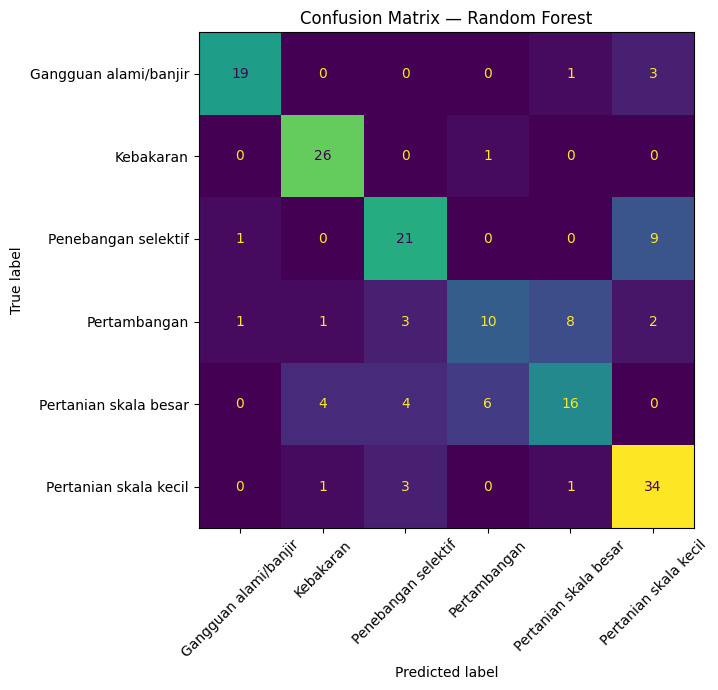

In [8]:
labels_urut = sorted(y.unique())
cm = confusion_matrix(y_test, pred_rf, labels=labels_urut)
fig, ax = plt.subplots(figsize=(10, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_urut)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — Random Forest")
plt.tight_layout()
plt.show()

In [9]:
model_dummy = DummyClassifier(strategy='most_frequent')
model_dummy.fit(X_train, y_train)
pred_dummy = model_dummy.predict(X_test)

perbandingan = pd.DataFrame([
    {
        'Model': 'DummyClassifier (kelas mayoritas)',
        'Accuracy': accuracy_score(y_test, pred_dummy),
        'Macro F1': f1_score(y_test, pred_dummy, average='macro')
    },
    {
        'Model': 'Random Forest',
        'Accuracy': accuracy_score(y_test, pred_rf),
        'Macro F1': f1_score(y_test, pred_rf, average='macro')
    }
])
display(perbandingan.round(3))

,Model,Accuracy,Macro F1
0,DummyClassifier (kelas mayoritas),0.223,0.061
1,Random Forest,0.720,0.709


In [10]:
contoh_alert = pd.DataFrame([{
    'luas_perubahan_ha': 5.4,
    'indikator_kedekatan_jalan_0_1': 0.72,
    'indikator_kebakaran_0_1': 0.12,
    'indikator_air_banjir_0_1': 0.20,
    'ketersediaan_optik_0_1': 0.80,
    'sinyal_radar_0_1': 0.69
}])
prediksi = model_rf.predict(contoh_alert)[0]
print("Prediksi driver (demonstrasi sintetis):", prediksi)
print("Jangan gunakan prediksi dummy ini sebagai bukti kondisi hutan nyata.")

Prediksi driver (demonstrasi sintetis): Pertanian skala besar
Jangan gunakan prediksi dummy ini sebagai bukti kondisi hutan nyata.


In [11]:
hasil = pd.DataFrame({
    'aktual': y_test.reset_index(drop=True),
    'prediksi_random_forest': pd.Series(pred_rf)
})
hasil.to_csv('hasil_prediksi_alert_dummy.csv', index=False)
perbandingan.to_csv('perbandingan_model_dummy.csv', index=False)
files.download('hasil_prediksi_alert_dummy.csv')
files.download('perbandingan_model_dummy.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>